In [1]:
# The scoring rule: A = 1, 2-10 = face value, J/Q/K = 10

CARD_VALUES = { 
    "A": 1,
    "2": 2, "3": 3, "4": 4, "5": 5,
    "6": 6, "7": 7, "8": 8, "9": 9,
    "10": 10, 
    "J": 10, "Q": 10, "K": 10,
}

def card_value(rank):
    """Input: rank string (e.g. "K", "A", "5").
    Returns: the points as an int. Returns 0 for an unrecognised rank
    (e.g. "unknown" from identify_card)."""
    return CARD_VALUES.get(rank,0)

# Running the tests

assert card_value("K") == 10
assert card_value("5") == 5
assert card_value("10") == 10
assert card_value("unknown") == 0

# Confirm tests have passed
print("All card_value tests passed!")

All card_value tests passed!


In [2]:
# Imports

import cv2
import numpy as np
from itertools import cycle

In [3]:
# Made in parallel programming using GenAI

def find_cards(image):
    """STAND-IN for Chris
    Input: original BGR img
    Output: list of (warped_card_img, contour) pairs
    Fakes two cards: black 200x300 images and rectangle contours
    placed at fixed spots, scaled to the photo size."""
    h,w = image.shape[:2]
    fake_boxes = [
        #x1,y1,x2,y2
        (int(w * 0.10), int(h * 0.20), int(w * 0.35), int(h * 0.80)),
        (int(w * 0.55), int(h * 0.20), int(w * 0.80), int(h * 0.80)),
    ]
    cards = []
    for x1, y1, x2, y2 in fake_boxes:
        #same shape as cv2.findContours output: (4,1,2) int32
        contour = np.array([
            [[x1, y1]], 
            [[x2,y1]], 
            [[x2, y2]], 
            [[x1, y2]]
            ], dtype = np.int32)
        warped = np.zeros((300,200,3), dtype=np.uint8)
        cards.append((warped,contour))
    return cards

_fake_results = cycle([("K", "hearts"), ("7", "spades"), ("A", "diamonds")])

def identify_card(card_img):
    """STAND-IN for Shibo
    Input: one straightened 200x300 card-image.
    Returns: (rank, suit). Cycles through fixed answers."""
    return next(_fake_results)

In [4]:
def run_pipeline(image):
    """Runs the full piepline on a BGR image.
    Returns: (results, total), where results is a list of 
    (rank, suit, contour) and total is the summed score."""
    results = []
    total = 0
    for warped, contour in find_cards(image):
        rank, suit = identify_card(warped)
        total += card_value(rank)
        results.append((rank, suit, contour))
    return results, total

In [5]:
# Testing new features
image_path = "test_images/4card.jpg"
image = cv2.imread(image_path)

if image is None:
    raise FileNotFoundError(f"Could not load {image_path}. Check path")

results, total = run_pipeline(image)

for rank, suit, _ in results:
    print(f"{rank} of {suit}: {card_value(rank)} points")
print("Total score:", total)

K of hearts: 10 points
7 of spades: 7 points
Total score: 17


In [6]:
import matplotlib.pyplot as plt

def draw_results(image,cards,total):
    """Draws each card outline, a label above it and the total score.
    Input: BGR image, cards = list of (rank, suit, contour), total = int
    Returns a new annoted image (the original is left untouched)"""
    output = image.copy()
    h, w = output.shape[:2]
    
    #scale line and text size to the photo so it's readable on big images
    scale = max(w,h) / 1000
    thickness = max(2, int(3 * scale))
    font_scale = max(0.6, scale)
    font = cv2.FONT_HERSHEY_SIMPLEX
    green = (0,255,0)
    
    for rank, suit, contour in cards:
        # outline around the card
        cv2.drawContours(output, [contour], -1, green, thickness)
        
        #label for the card (typically above but inside it if the card touches the top edge)
        x,y,bw,bh = cv2.boundingRect(contour)
        label_y = y - 10 if y>40*scale else y + int(30 * scale)
        cv2.putText(output, f"{rank} {suit}", (x, label_y),
                    font, font_scale, green, thickness)
        
    # total for the top left: black outline first so its readable on any bg
    total_text = f"Total: {total}"
    pos = (int(15*scale), int(50*scale))
    cv2.putText(output, total_text, pos, font, font_scale * 1.3, (0,0,0), thickness + 3)
    cv2.putText(output, total_text, pos, font, font_scale * 1.3, (255,255,255), thickness)
        
    
    return output

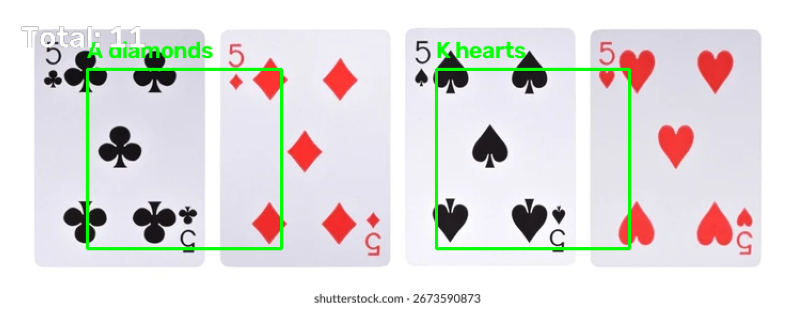

In [7]:
results, total = run_pipeline(image)
annotated = draw_results(image, results, total)

cv2.imwrite("result.png", annotated)

plt.figure(figsize=(10,7))
plt.imshow(cv2.cvtColor(annotated, cv2.COLOR_BGR2RGB))
plt.axis("off")
plt.show()